# 0. Setup

Libraries, random seed and compute device. The seed (33) is fixed for Python, NumPy and PyTorch so that weight initialisation, shuffling and dropout are repeatable, and the same results can be reproduced when the notebook is rerun. It was chosen arbitrarily and not tuned against any score. Results can still vary slightly across different hardware. Environment: Python 3.11.0rc2, PyTorch 2.14.1, device `mps`.


In [1]:
# Imports, environment setup, SLOT_RE regex, and random seeds

import matplotlib.pyplot as plt, numpy as np, pandas as pd
import random,  torch, sys, json, re
from collections import defaultdict, Counter

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("torch:", torch.__version__)
print("device:", device)

SLOT_RE = re.compile(r"\[([^\[\]:]+?)\s*:\s*([^\[\]]+?)\]")

SEED = 33
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

Python: 3.11.0rc2
torch: 2.14.1
device: mps


# 1. Load and verify the dataset

Source: MASSIVE 1.0, English (en-US), file `en-US.jsonl`. Records are grouped by the official `partition` field (no re-splitting). The asserts check the sizes required by the brief: 11,514 train, 2,033 dev, 2,974 test (16,521 in total).

In [2]:
# Load en-US.jsonl and group records by partition 
splits = {"train": [], "dev": [], "test": []}
with open("en-US.jsonl", "r") as f:
    for line in f:
        data = json.loads(line)
        if data["partition"] == "train":
            splits["train"].append(data)
        elif data["partition"] == "dev":
            splits["dev"].append(data)
        elif data["partition"] == "test":
            splits["test"].append(data)

print(f"Train set size: {len(splits['train'])}")
print(f"Dev set size: {len(splits['dev'])}")
print(f"Test set size: {len(splits['test'])}")

assert len(splits["train"]) == 11514
assert len(splits["dev"]) == 2033
assert len(splits["test"]) == 2974

Train set size: 11514
Dev set size: 2033
Test set size: 2974


# 2. Exploratory data analysis (train only)

All design statistics use the training split only, so the dev and test sets do not influence design decisions.

In [3]:
# 1. Count the intents in training data
train_intent_counter = Counter(r["intent"] for r in splits["train"])

print("Train intent counts:")
for intent, count in train_intent_counter.most_common():
    print(f"  {intent}: {count}")

print(f"Number of intents in train: {len(train_intent_counter)}")
print(f"Total train examples: {sum(train_intent_counter.values())}")

assert len(train_intent_counter) == 60

Train intent counts:
  calendar_set: 810
  play_music: 639
  weather_query: 573
  calendar_query: 566
  general_quirky: 555
  qa_factoid: 544
  news_query: 503
  email_query: 418
  email_sendemail: 354
  datetime_query: 350
  calendar_remove: 312
  play_radio: 283
  social_post: 283
  qa_definition: 267
  transport_query: 227
  cooking_recipe: 207
  lists_query: 198
  play_podcasts: 193
  recommendation_events: 190
  alarm_set: 182
  lists_createoradd: 177
  recommendation_locations: 173
  lists_remove: 164
  music_query: 154
  iot_hue_lightoff: 153
  qa_stock: 152
  play_audiobook: 150
  qa_currency: 142
  takeaway_order: 135
  alarm_query: 130
  transport_ticket: 127
  email_querycontact: 127
  iot_hue_lightchange: 125
  iot_coffee: 124
  takeaway_query: 122
  transport_traffic: 117
  music_likeness: 113
  play_game: 112
  audio_volume_mute: 110
  audio_volume_up: 110
  social_query: 108
  transport_taxi: 100
  iot_cleaning: 93
  alarm_remove: 78
  qa_maths: 78
  iot_hue_lightdim: 76

**Intents:** 60 intents, with an uneven distribution (the largest, `calendar_set`, has 810 training examples). Accuracy should be read with this imbalance in mind.

In [4]:
# 2. Seeing the slot types and their counts in training data
slot_counts = Counter()
for r in splits["train"]:
    for slot_type, span in SLOT_RE.findall(r["annot_utt"]):
        slot_counts[slot_type.strip()] += 1

print("Number of slot types:", len(slot_counts))
for s, n in slot_counts.most_common():
    print(f"{s:30s} {n}")

assert len(slot_counts) == 55

Number of slot types: 55
date                           1816
place_name                     1086
event_name                     998
person                         864
time                           797
media_type                     477
business_name                  383
weather_descriptor             320
transport_type                 318
food_type                      295
relation                       251
timeofday                      239
artist_name                    232
device_type                    226
definition_word                225
currency_name                  217
house_place                    198
list_name                      191
business_type                  189
news_topic                     183
music_genre                    181
player_setting                 160
radio_name                     131
song_name                      128
order_type                     107
color_type                     100
game_name                      87
general_frequency            

**Slot types:** 55 types, also uneven (`date` has 1,816 spans, the most frequent). Rare types will be harder to learn, so slot F1 is likely to be lowest on them.

Mean:            6.92
Median:          6
Max:             35
95th percentile: 13


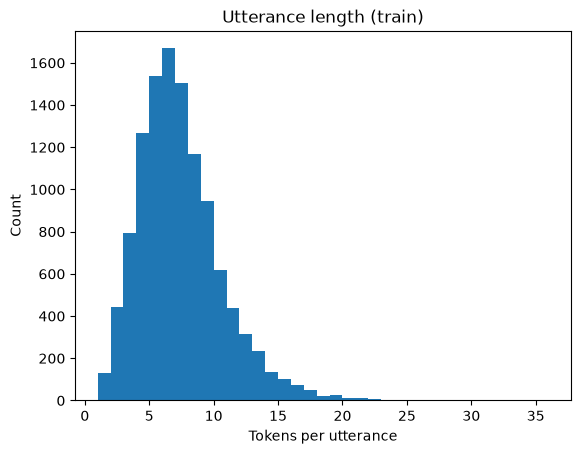

In [5]:
# 3. Utterance length in training data
lengths = np.array([len(r["utt"].split()) for r in splits["train"]])

print(f"Mean:            {lengths.mean():.2f}")
print(f"Median:          {np.median(lengths):.0f}")
print(f"Max:             {lengths.max()}")
print(f"95th percentile: {np.percentile(lengths, 95):.0f}")

plt.hist(lengths, bins=range(1, lengths.max() + 2))
plt.xlabel("Tokens per utterance"); plt.ylabel("Count")
plt.title("Utterance length (train)")
plt.show()

**Utterance length:** mean 6.92 words, median 6, 95th percentile 13, maximum 35. Utterances are short. Padding to the longest sentence in each batch is cheap, and nothing needs truncating.

In [6]:
# 4. Slot per utterance in training data
per_utt = Counter(min(len(SLOT_RE.findall(r["annot_utt"])), 2) for r in splits["train"])
print("0 slots:", per_utt[0], "| 1 slot:", per_utt[1], "| 2+ slots:", per_utt[2])

0 slots: 3755 | 1 slot: 5074 | 2+ slots: 2685


**Slots per utterance:** 3,755 (32.6%) have no slots, 5,074 (44.1%) have one, 2,685 (23.3%) have two or more. An all-`O` tag sequence is a common valid answer, so the label format and the F1 code must handle an empty slot set.

In [7]:
# 5. Slot spans in training data
span_lengths = [
    len(span.split())
    for r in splits["train"]
    for _, span in SLOT_RE.findall(r["annot_utt"])
]

total = len(span_lengths)
single = sum(1 for n in span_lengths if n == 1)
multi = total - single

print(f"Total slot spans: {total}")
print(f"Single-word:      {single} ({100 * single / total:.2f}%)")
print(f"Multi-word:       {multi} ({100 * multi / total:.2f}%)")

# Breakdown by exact length
for n, c in sorted(Counter(span_lengths).items()):
    print(f"  {n} word(s): {c}")


Total slot spans: 11344
Single-word:      7008 (61.78%)
Multi-word:       4336 (38.22%)
  1 word(s): 7008
  2 word(s): 2903
  3 word(s): 993
  4 word(s): 202
  5 word(s): 131
  6 word(s): 60
  7 word(s): 35
  8 word(s): 6
  9 word(s): 3
  10 word(s): 3


**Slot span length:** of 11,344 spans, 61.78% are one word and 38.22% are multi-word (up to 10 words). Multi-word spans need correct `B-`/`I-` boundaries, and exact-match F1 penalises any boundary error, so boundary quality matters for the slot score.

In [8]:
# 6. Number of unique words, and how many appear only once? (training data)
word_counts = Counter(w for r in splits["train"] for w in r["utt"].split())
print("Unique words:", len(word_counts))
print("Appear once:", sum(1 for c in word_counts.values() if c == 1))

Unique words: 5302
Appear once: 2537


**Vocabulary:** 5,302 unique words, of which 2,537 (about 48%) appear only once in train. Many dev/test words will be unseen, so an `<unk>` token is needed, and pretrained word vectors or character-level features are worth considering.

In [9]:
# 7. Odd characters in training data (apostrophes, hyphens, digits, symbols)
odd = Counter(ch for r in splits["train"] for ch in r["utt"]
              if not (ch.isalpha() or ch == " "))
print(odd.most_common())

[('.', 1299), ("'", 952), ('-', 35), ('&', 5), ('<', 1), ('>', 1)]


**Odd characters:** `.` (1,299), `'` (952), `-` (35), `&` (5), `<` and `>` (1 each); no digits. Punctuation is attached to words (for example `what's`), so the tokenizer keeps it attached, to match `annot_utt`.

In [10]:
# 8. Do different intents use different slots? (training data)
intent_slots = defaultdict(Counter)
for r in splits["train"]:
    for t, _ in SLOT_RE.findall(r["annot_utt"]):
        intent_slots[r["intent"]][t.strip()] += 1
for intent, c in sorted(intent_slots.items()):
    print(f"{intent:28s} {len(c):2d} slot types | top: {dict(c.most_common(3))}")

alarm_query                   7 slot types | top: {'date': 28, 'timeofday': 14, 'time': 11}
alarm_remove                  6 slot types | top: {'time': 25, 'date': 20, 'timeofday': 9}
alarm_set                     9 slot types | top: {'time': 141, 'date': 53, 'timeofday': 24}
audio_volume_down             2 slot types | top: {'change_amount': 6, 'device_type': 1}
audio_volume_mute             5 slot types | top: {'time': 22, 'device_type': 4, 'change_amount': 2}
audio_volume_other            1 slot types | top: {'change_amount': 1}
audio_volume_up               4 slot types | top: {'change_amount': 19, 'device_type': 6, 'song_name': 1}
calendar_query               12 slot types | top: {'date': 298, 'event_name': 217, 'time': 73}
calendar_remove              12 slot types | top: {'date': 107, 'event_name': 105, 'time': 25}
calendar_set                 16 slot types | top: {'event_name': 530, 'date': 421, 'time': 271}
cooking_query                 2 slot types | top: {'food_type': 2, 'mea

**Intents vs slot types:** different intents use different slot types (for example `alarm_set` uses mostly `time` and `date`), so knowing the intent is informative for slot filling. This motivates a joint model.

# 3. Preprocessing
**Tokenisation:** whitespace split of `utt`, with punctuation kept attached.

**Parsing `annot_utt`:** `parse_annot` walks the string left to right, removing the brackets and recording character offsets as it goes. Because positions come from the walk and not from text search, repeated span text cannot be misplaced. `slots_to_word_positions` converts offsets to word indices (end index inclusive).

**Label format:** BIO tags per word (`O`, `B-<type>`, `I-<type>`), 2 × 55 + 1 = 111 tags. The intent is one of 60 classes. The tag set is built from the 55 slot types seen in train, not from the tags observed in train: only 107 of the 111 tags occur in the training data (four `I-` tags never appear, because those slot types only have single-word spans there), and the test set contains one of them (`I-transport_type`). Building from the slot types keeps the map complete without using dev or test information.

**Checks (all three splits):** plain text equals `utt` (0 mismatches), tokens match `utt.split()` and tags are aligned (0 failures), and decoding tags back to spans reproduces the gold spans (0 round-trip failures).

In [11]:
example = "wake me up at [time : nine am] on [date : friday]"

for m in SLOT_RE.finditer(example):
    print("type:", m.group(1).strip(), "| words:", m.group(2).strip())

type: time | words: nine am
type: date | words: friday


In [12]:
# Print each slot and the bracket-free text for the first 5 training rows
for r in splits["train"][:5]:
    annot_utt = r.get("annot_utt", "")
    
    print(f"--- Row ID: {r.get('id')} ---")
    print(f"Utterance: {annot_utt}")
    
    # Iterate through all slot matches in the annotated utterance
    for m in SLOT_RE.finditer(annot_utt):
        slot_type = m.group(1).strip()
        slot_words = m.group(2).strip()
        print(f"  type: {slot_type} | words: {slot_words}")

    plain = SLOT_RE.sub(lambda m: m.group(2).strip(), annot_utt)
    print("Plain:", plain)
    print("Same as utt?", plain == r["utt"])

--- Row ID: 1 ---
Utterance: wake me up at [time : nine am] on [date : friday]
  type: time | words: nine am
  type: date | words: friday
Plain: wake me up at nine am on friday
Same as utt? True
--- Row ID: 2 ---
Utterance: set an alarm for [time : two hours from now]
  type: time | words: two hours from now
Plain: set an alarm for two hours from now
Same as utt? True
--- Row ID: 4 ---
Utterance: olly quiet
Plain: olly quiet
Same as utt? True
--- Row ID: 5 ---
Utterance: stop
Plain: stop
Same as utt? True
--- Row ID: 6 ---
Utterance: olly pause for [time : ten seconds]
  type: time | words: ten seconds
Plain: olly pause for ten seconds
Same as utt? True


In [13]:
# mismatches between annotated utterance and plain utterance
# If mismatch = 0, words that were extracted from the brackets sit in the right places in the sentence, 
# so we can safely work out which words are in each slot.

bad = []
for name, rows in splits.items():
    for r in rows:
        plain = SLOT_RE.sub(lambda m: m.group(2).strip(), r["annot_utt"])
        if plain != r["utt"]:
            bad.append((name, r["id"], r["utt"], plain))

print("Mismatches:", len(bad))
for x in bad[:5]:
    print(x)

Mismatches: 0


In [14]:
# Remove brackets from annot_utt and record each slot's (type, text, char_start, char_end), built
# in one left-to-right pass

def parse_annot(annot_utt):
    plain = ""
    slots = []
    last = 0 

    for m in SLOT_RE.finditer(annot_utt):
        plain += annot_utt[last:m.start()]
        start = len(plain) 
        words = m.group(2).strip()
        plain += words
        end = len(plain)     
        slots.append((m.group(1).strip(), words, start, end))
        last = m.end()

    plain += annot_utt[last:] 
    return plain, slots

In [15]:
# Test parse_annot: slicing plain at the character offsets must return the span text

plain, slots = parse_annot("wake me up at [time : nine am] on [date : friday]")
print(repr(plain))
for s in slots:
    print(s, "->", repr(plain[s[2]:s[3]]))

'wake me up at nine am on friday'
('time', 'nine am', 14, 21) -> 'nine am'
('date', 'friday', 25, 31) -> 'friday'


In [16]:
# Split plain text on whitespace, keeping each word's character start and end 

def tokenize_with_offsets(plain):
    tokens = []   # each: (word, char_start, char_end)
    for m in re.finditer(r"\S+", plain):     # \S+ = a run of non-space characters
        tokens.append((m.group(), m.start(), m.end()))
    return tokens

In [17]:
# Convert character offsets into word indices (first word, last word, end inclusive)

def slots_to_word_positions(slots, tokens):
    result = []
    for slot_type, words, c_start, c_end in slots:
        covered = [i for i, (_, t_start, t_end) in enumerate(tokens)
                   if t_start >= c_start and t_end <= c_end]
        result.append((slot_type, words, covered[0], covered[-1]))
    return result

In [18]:
# Test the character-to-word conversion on the same example

plain, slots = parse_annot("wake me up at [time : nine am] on [date : friday]")
tokens = tokenize_with_offsets(plain)
print(tokens)
print(slots_to_word_positions(slots, tokens))

[('wake', 0, 4), ('me', 5, 7), ('up', 8, 10), ('at', 11, 13), ('nine', 14, 18), ('am', 19, 21), ('on', 22, 24), ('friday', 25, 31)]
[('time', 'nine am', 4, 5), ('date', 'friday', 7, 7)]


In [19]:
# Turn word-level slots into one BIO tag per word (B-type, I-type, O)

def make_bio_tags(num_tokens, word_slots):
    tags = ["O"] * num_tokens
    for slot_type, words, w_start, w_end in word_slots:
        tags[w_start] = "B-" + slot_type
        for i in range(w_start + 1, w_end + 1):
            tags[i] = "I-" + slot_type
    return tags

In [20]:
# Test make_bio_tags: expect B-time I-time ... B-date

word_slots = slots_to_word_positions(slots, tokens)
tags = make_bio_tags(len(tokens), word_slots)
print(list(zip([t[0] for t in tokens], tags)))

[('wake', 'O'), ('me', 'O'), ('up', 'O'), ('at', 'O'), ('nine', 'B-time'), ('am', 'I-time'), ('on', 'O'), ('friday', 'B-date')]


In [21]:
# Run the whole pipeline on one example, returning plain text, tokens, BIO tags, and word-level slots

def process_example(r):
    plain, slots = parse_annot(r["annot_utt"])
    tokens = tokenize_with_offsets(plain)
    word_slots = slots_to_word_positions(slots, tokens)
    tags = make_bio_tags(len(tokens), word_slots)
    return plain, [t[0] for t in tokens], tags, word_slots

In [22]:
# Check all splits: plain text == utt, words == utt.split(), len(tags) == len(words)

failures = []
for name, rows in splits.items():
    for r in rows:
        try:
            plain, words, tags, _ = process_example(r)
            assert plain == r["utt"]
            assert words == r["utt"].split()
            assert len(tags) == len(words)
        except Exception as e:
            failures.append((name, r["id"], repr(e)))

print("Failures:", len(failures))
print(failures[:5])


Failures: 0
[]


In [23]:
# Print the first 5 training examples as (word, tag) pairs to check

for r in splits["train"][:5]:
    plain, words, tags, word_slots = process_example(r)
    print(list(zip(words, tags)))
    print(word_slots)

[('wake', 'O'), ('me', 'O'), ('up', 'O'), ('at', 'O'), ('nine', 'B-time'), ('am', 'I-time'), ('on', 'O'), ('friday', 'B-date')]
[('time', 'nine am', 4, 5), ('date', 'friday', 7, 7)]
[('set', 'O'), ('an', 'O'), ('alarm', 'O'), ('for', 'O'), ('two', 'B-time'), ('hours', 'I-time'), ('from', 'I-time'), ('now', 'I-time')]
[('time', 'two hours from now', 4, 7)]
[('olly', 'O'), ('quiet', 'O')]
[]
[('stop', 'O')]
[]
[('olly', 'O'), ('pause', 'O'), ('for', 'O'), ('ten', 'B-time'), ('seconds', 'I-time')]
[('time', 'ten seconds', 3, 4)]


In [24]:
# decode_bio: inverse of make_bio_tags, returning a list of (slot_type, span_text, w_start, w_end) for each span

def decode_bio(words, tags):
    """BIO tags -> list of (slot_type, span_text, w_start, w_end)."""
    spans = []
    cur_type, cur_start = None, None
    for i, tag in enumerate(tags + ["O"]):
        if tag.startswith("B-") or tag == "O" or (
            tag.startswith("I-") and tag[2:] != cur_type
        ):
            if cur_type is not None:
                spans.append((cur_type, " ".join(words[cur_start:i]), cur_start, i - 1))
                cur_type, cur_start = None, None
            if tag.startswith("B-") or tag.startswith("I-"):
                cur_type, cur_start = tag[2:], i
    return spans


In [25]:
# Run roundtrip over every example 

roundtrip_bad = []
for name, rows in splits.items():
    for r in rows:
        plain, words, tags, word_slots = process_example(r)
        if decode_bio(words, tags) != word_slots:
            roundtrip_bad.append((name, r["id"]))

print("Roundtrip failures:", len(roundtrip_bad))

Roundtrip failures: 0


In [26]:
# Which BIO tags occur in each split? (the tag set itself is built from slot types, not from this)
def observed_tags(rows):
    s = set()
    for r in rows:
        for t in process_example(r)[2]:
            s.add(t)
    return s

train_tags = observed_tags(splits["train"])
all_tags = {"O"} | {p + t for t in slot_counts for p in ("B-", "I-")}
print("Full tag set:", len(all_tags), "| observed in train:", len(train_tags))
print("Never seen in train:", sorted(all_tags - train_tags))
print("In dev but not train: ", sorted(observed_tags(splits["dev"]) - train_tags))
print("In test but not train:", sorted(observed_tags(splits["test"]) - train_tags))
assert len(all_tags) == 111

Full tag set: 111 | observed in train: 107
Never seen in train: ['I-cooking_type', 'I-email_folder', 'I-game_type', 'I-transport_type']
In dev but not train:  []
In test but not train: ['I-transport_type']


# 4. Evaluation functions
**Intent accuracy:** 100 × correct predictions / number of utterances.

**Slot micro-F1:** exact match on (slot type, span text) pairs, pooled over all utterances. TP = pair in both gold and prediction, FP = predicted but not gold, FN = gold but not predicted. F1 = 100 × 2TP / (2TP + FP + FN). Duplicate pairs within one utterance are counted separately (multiset comparison). An empty gold set and empty prediction set are handled without division by zero.

**Tests (cell below, with asserts):** expected values were worked out by hand from F1 = 100 × 2TP / (2TP + FP + FN), and any edit that breaks a metric makes the cell fail. Slot cases: perfect predictions (100.00); no slots found (0.00); wrong slot type with the right text (0.00); a near-miss span such as `("time","nine")` for `("time","nine am")` (0.00, because the span must match exactly); an extra predicted slot, FP only (66.67); a missed slot, FN only (66.67); one correct and one wrong slot, 1 TP + 1 FP + 1 FN (50.00); a real dev example with a repeated slot (`[person : david]` twice, id 15805) predicted in full (100.00) and with one copy missing; empty gold and empty prediction pooled with a correct utterance (100.00); and an empty gold with a prediction (0.00). Both metrics assert that the gold and prediction lists have equal length, and a mismatch is tested to raise an error. Intent accuracy is tested at 100.00 and 50.00. Decoding of invalid tag sequences is tested too (below).

**Invalid tag sequences:** a model may output an `I-x` tag that does not continue an open `x` span (for example `O I-time` or `B-time I-date`). `decode_bio` treats such a tag as the start of a new span of type `x`, so no predicted word is dropped, and `O I-time I-time` decodes to one `time` span.

In [27]:
# Intent accuracy

def intent_accuracy(gold_intents, pred_intents):
    assert len(gold_intents) == len(pred_intents), "gold/pred length mismatch"
    
    correct = sum(g == p for g, p in zip(gold_intents, pred_intents))
    return 100 * correct / len(gold_intents)

In [28]:
# Slot micro F1 score

def slot_micro_f1(gold_pairs_list, pred_pairs_list):
    assert len(gold_pairs_list) == len(pred_pairs_list), "gold/pred length mismatch"
    
    tp = fp = fn = 0
    for gold, pred in zip(gold_pairs_list, pred_pairs_list):
        g, p = Counter(gold), Counter(pred)
        overlap = sum((g & p).values())      # multiset intersection
        tp += overlap
        fp += sum(p.values()) - overlap
        fn += sum(g.values()) - overlap
    denom = 2 * tp + fp + fn
    return 100 * 2 * tp / denom if denom else 0.0

In [29]:
# Tags -> (type, text) pairs. Used for BOTH gold and predictions so they go through identical code.
def tags_to_pairs(words, tags):
    return [(t, text) for t, text, _, _ in decode_bio(words, tags)]

In [30]:
# Metric tests with hand-computed expected values; any edit that breaks the metrics fails loudly
def close(a, b): return abs(a - b) < 0.01

A, B, C = ("time", "nine am"), ("date", "friday"), ("place_name", "paris")

# perfect, and no slots found
assert close(slot_micro_f1([[A, B]], [[A, B]]), 100.0)
assert close(slot_micro_f1([[A, B]], [[]]), 0.0)
# wrong type, same text: TP=0 FP=1 FN=1
assert close(slot_micro_f1([[("time", "nine am")]], [[("date", "nine am")]]), 0.0)
# near-miss span: exact match needed
assert close(slot_micro_f1([[("time", "nine am")]], [[("time", "nine")]]), 0.0)
# extra predicted slot (FP only): TP=1 FP=1 FN=0 -> 66.67
assert close(slot_micro_f1([[A]], [[A, B]]), 200 / 3)
# missed slot (FN only): TP=1 FP=0 FN=1 -> 66.67
assert close(slot_micro_f1([[A, B]], [[A]]), 200 / 3)
# partly correct: TP=1 FP=1 FN=1 -> 50.00
assert close(slot_micro_f1([[A, B]], [[A, C]]), 50.0)

# repeated slot, using a real dev example (id 15805: [person : david] appears twice)
rec = next(r for r in splits["dev"] if r["id"] == "15805")
words, tags = process_example(rec)[1:3]
dup_gold = tags_to_pairs(words, tags)
assert dup_gold.count(("person", "david")) == 2
assert close(slot_micro_f1([dup_gold], [dup_gold]), 100.0)
once = [p for p in dup_gold if p != ("person", "david")] + [("person", "david")]
assert close(slot_micro_f1([dup_gold], [once]), 100 * 2 * (len(dup_gold) - 1) / (2 * (len(dup_gold) - 1) + 1))

# one empty-gold/empty-pred utterance pooled with a correct one: still 100
assert close(slot_micro_f1([[], [A]], [[], [A]]), 100.0)
# empty gold but a prediction (pure FP) -> 0; no division by zero when everything is empty
assert close(slot_micro_f1([[]], [[A]]), 0.0)
assert close(slot_micro_f1([[]], [[]]), 0.0)   # convention: undefined case returns 0.0

# length mismatch must raise
try:
    slot_micro_f1([[A]], [[A], [B]]); raise SystemExit("length check missing")
except AssertionError:
    pass

# invalid tag sequences (decoding policy)
assert tags_to_pairs(["x", "y", "z"], ["O", "I-time", "I-time"]) == [("time", "y z")]
assert tags_to_pairs(["x", "y"], ["B-time", "I-date"]) == [("time", "x"), ("date", "y")]

# intent accuracy
assert close(intent_accuracy(["a", "b"], ["a", "b"]), 100.0)
assert close(intent_accuracy(["a", "b"], ["a", "c"]), 50.0)

print("All metric tests passed")

All metric tests passed


# Phase 1 handover (to Phase 2) - to be deleted before submitting

Everything below is already built, tested and committed in this notebook. Phase 2 can use it without reading the implementation.

## 1. Data
`splits["train"]`, `splits["dev"]`, `splits["test"]`: lists of raw MASSIVE records. Sizes are asserted (11,514 / 2,033 / 2,974).

## 2. Functions

| Function | Input | Output | Used in Phase 2 for |
|---|---|---|---|
| `process_example(r)` | one record | `plain, words, tags, word_slots` | Model inputs (`words`) and slot targets (`tags`) for every split |
| `tags_to_pairs(words, tags)` | list of words and a list of tag **strings** (same length) | `[(slot_type, span_text), ...]` | Converting gold tags and predicted tags to metric input |
| `intent_accuracy(gold, pred)` | two equal-length lists of intent strings | percentage | Per-epoch dev and final evaluation |
| `slot_micro_f1(gold, pred)` | two equal-length lists, one list of `(type, text)` pairs per utterance | percentage | Same |

## 3. Facts to know
- Tokens are `utt.split()`, with punctuation kept attached. There is one tag per word.
- 60 intents. Slot tags are BIO over 55 slot types: `O` plus `B-` and `I-` for each type = **111 tags**. Build `tag2id` from the 55 slot types (taken from train), **not** from the tags observed in train: only 107 of the 111 occur in train, and the test set contains `I-transport_type`, which never occurs in train.
- All dev and test intents and slot types occur in train, so intent and slot-type maps built from train are complete.
- The model outputs numbers. Map predicted ids back to tag strings, and cut off padding so the tag list has exactly `len(words)` entries, before calling `tags_to_pairs`.
- Invalid tag sequences (for example `O I-time`) are handled by `decode_bio` (an `I-` tag that does not continue the open span starts a new span), so model output does not need fixing first.
- Fix the tag order. For example, sort the 55 types, then give O ID 0. That way tag2id comes out identical every run, and a saved checkpoint reloads with the right labels. The same applies to intents.
- The model has never seen I-transport_type in training. A multiword transport_type span in test will therefore almost certainly be missed. This is a data limitation rather than a bug. It's worth flagging to Phase 2 now, because it's a natural candidate for the error analysis later.

## 4. Rules
- Do not edit `intent_accuracy`, `slot_micro_f1`, `tags_to_pairs` or `decode_bio`. Both stages must be scored identically, and the metric tests above will fail if they are changed.
- Vocabulary and label maps use the train split only.
- Use dev for choosing the epoch and settings. Use test only once at the end.

## 5. Not done yet (Phase 2)
- Word vocabulary with `<pad>` and `<unk>`.
- Word, tag and intent id maps.
- Padding and batching, and masking padded positions out of the slot loss.

## 6. Data findings to keep in mind (details in Section 2)
- Intent classes are imbalanced (largest: 810 train examples).
- 32.6% of utterances have no slots.
- 38.2% of slot spans are multi-word.
- About 48% of training words appear only once: Use `<unk>` handling, and consider pretrained word vectors or character features.